In [5]:
# function to read the object ids from the parquet files 
import pandas as pd
from pathlib import Path
from object_id_classification import collect_classifier_scores

input_path = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\raw\fink_alerts\extragalactic_candidates_using_SNGC.parquet")
object_ids = pd.read_parquet(input_path)["diaObjectId"].tolist()

collect_classifier_scores(object_ids)

#print(f"The object Ids in this Parquet file are {object_ids}")

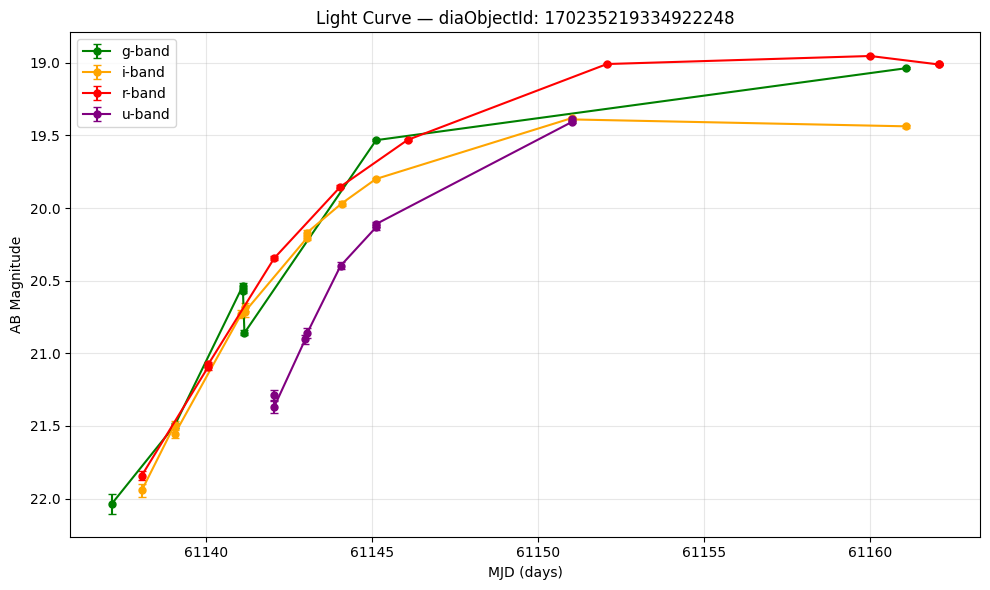

<Figure size 640x480 with 0 Axes>

In [2]:
# fast plotter of the light curves for the object IDs
import io
import requests
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

OBJECT_ID = "170235219334922248"

def fetch_lightcurve(diaObjectId: str) -> pd.DataFrame:
    r = requests.post(
        "https://api.lsst.fink-portal.org/api/v1/sources",
        json={
            "diaObjectId": diaObjectId,
            "columns": "r:diaSourceId,r:midpointMjdTai,r:psfFlux,r:psfFluxErr,r:band",
            "output-format": "json",
        },
    )
    r.raise_for_status()
    return pd.read_json(io.BytesIO(r.content))

def flux_to_mag(flux, flux_err):
    """Convert nanojansky flux to AB magnitude with propagated uncertainty."""
    mag = -2.5 * np.log10(flux) + 31.4
    mag_err = (2.5 / np.log(10)) * (flux_err / flux)
    return mag, mag_err

def plot_lightcurve(df: pd.DataFrame, diaObjectId: str):
    # Filter out negative flux (non-detections)
    df = df[df["r:psfFlux"] > 0].copy()

    df["mag"], df["mag_err"] = flux_to_mag(df["r:psfFlux"], df["r:psfFluxErr"])

    band_colours = {"u": "purple", "g": "green", "r": "red", "i": "orange", "z": "black", "y": "brown"}

    fig, ax = plt.subplots(figsize=(10, 6))

    for band, group in df.groupby("r:band"):
        colour = band_colours.get(band, "black")
        ax.errorbar(
            group["r:midpointMjdTai"],
            group["mag"],
            yerr=group["mag_err"],
            fmt="o-",
            color=colour,
            label=f"{band}-band",
            capsize=3,
            markersize=5,
        )

    ax.invert_yaxis()  # Magnitudes are inverted — brighter = smaller number
    ax.set_xlabel("MJD (days)")
    ax.set_ylabel("AB Magnitude")
    ax.set_title(f"Light Curve — diaObjectId: {diaObjectId}")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.savefig('170235219334922248_light_curve.png')

df = fetch_lightcurve(OBJECT_ID)
plot_lightcurve(df, OBJECT_ID)